## Задание 4: Получение постов пользователя

Выполнил: Ларюшкин Кирилл Александрович

Группа: 292605


```bash
python -m venv venv
venv\Scripts\activate
pip install requests
pip freeze > requirements.txt
```

In [ ]:
import requests  # Импорт модуля request
import logging  # Импорт модуля logging


# Настройка логирования
logging.basicConfig(
    filename='task4.log',  # Файл куда сохранять логи
    filemode='w',  # Режим - перезаписывать файл с логами при запуске
    level=logging.DEBUG,  # Определениение уровня логирования - уровень логирования DEBUG и выше
    format='%(asctime)s - %(levelname)s - %(message)s',  # Формат логов
    encoding='UTF-8',  # Кодировка UTF-8 , для корректного отображения кириллицы 
)


def get_posts(userId: int):
    """ Функция просмотра постов авторов 
    Получает в аргуементах userId, делает GEt запрос на https://dummyjson.com/users/{userId}/posts
    Выводит сообщение с количеством постов у автора, номер поста и его название
    """
    
    try:
        # Обработка исключения если пользователь введет не число , а строку, то вызовет ошибку ValueError и сообщение
        if int(userId):
            logging.info(f'Получение данных о постах пользователя с id {userId}. Обращение к API ...')
            
            url = f'https://dummyjson.com/users/{userId}/posts'  # формируем url эндопинта к котору обращаемся

            response = requests.get(url, timeout=10)  # GET обращение к эндпоинту с таймаутом
            response.raise_for_status()  # контроль статус-кодов ответа для отравливания ошибок
            
            data = response.json()  # преобразуем ответ в список
    
            posts = data.get('posts', [])  # получаем список содержимого словаря posts, если в ответе данных нет, формируем пустой список

            # Если у выбраного пользователя нет постов, сразу возвращаем об этом информацию и просьбу выбрать другого, и не выполняем дальнейший код
            if len(posts) == 0:
                logging.info(f'У выбранного автора с ID {userId} нет постов')
                print(f'У Автора с ID {userId} нет постов. Пожалуйста, выберете другого') # Сообщение пользователю

             # Если у искомого пользователя есть посты, выводим их
            else:
                print(f'У автора c id {userId} - {len(posts)} поста/ов ')
                print(f'Публикации: ')  # Сообщение с информацией какому пользователю принадлежат посты
                
                for post in posts:  # Проходимся циклом по постам и формируем сообщение id поста и его название
                    print(f'Пост №{post["id"]}. Название поста - {post["title"]}')

                logging.info(f'Обращение прошло успешно. Выведены на экран {len(posts)} поста автора с id {userId}')

    except requests.exceptions.HTTPError as e: # Обрабатывает случай, когда запрос был успешно отправлено сервер его обработал, но вернул статус-код указывающий на ошибку
        logging.error(f'Обращение к серверу прошло успешно, сервер его обработал но вернул ошибку : {e}')  # Логирует ошибку
        print(f'Обращение к серверу прошло успешно, сервер его обработал но вернул ошибку : {e}')  # Вовзращаем сообщение с ошибкой

    except requests.exceptions.RequestException as e:  # Обрабатывает ошибки при обращении к API
        logging.error(f'Произошла ошибка:{e}')  # Логирует ошибку
        print(f'Произошла ошибка: {e}')  # Вовзращаем сообщение с ошибкой

    except (TypeError, ValueError) as e:  # Обрабатывает ошибки при обработки данных
        logging.error(f'Ошибка типа данных:{e}')  # Логирует ошибку
        print(f'Ошибка типа данных. Пожалуйста введите ID автора в виде целого числа:{e}') # Вовзращаем сообщение с ошибкой


if __name__ == '__main__':   # Запускать можно только из главного файла, импортировать нельзя
    
    while True:
        userId = input('Введите id пользователя посты которого хотите посмотреть: \nЧто бы выйти ведите "q"\n').strip()   # Сразу обозначаем id пользователя
        
        # Выход из программы
        if userId == 'q': 
            print('Работа программы завершена')
            break
            
        logging.info(f'Пользователь хочет найти посты автора с ID: {userId}')
        get_posts(userId)   # Вызов функции с передачей аргумента в виде id пользователя
       
    


Введите id пользователя посты которого хотите посмотреть: 
Что бы выйти ведите "q"
 1


У автора c id 1 - 1 поста/ов 
Публикации: 
Пост №15. Название поста - The trees, therefore, must be such old


Введите id пользователя посты которого хотите посмотреть: 
Что бы выйти ведите "q"
 2


У автора c id 2 - 2 поста/ов 
Публикации: 
Пост №183. Название поста - The bustling marketplace
Пост №218. Название поста - The bustling city street was a feast for the senses


Введите id пользователя посты которого хотите посмотреть: 
Что бы выйти ведите "q"
 3


У Автора с ID 3 нет постов. Пожалуйста, выберете другого


... (12 outputs left out)

Введите id пользователя посты которого хотите посмотреть: 
Что бы выйти ведите "q"
 dfgdfg  


Ошибка типа данных. Пожалуйста введите ID автора в виде целого числа:invalid literal for int() with base 10: 'dfgdfg'


Введите id пользователя посты которого хотите посмотреть: 
Что бы выйти ведите "q"
 q


Работа программы завершена


```bash
deactivate
```

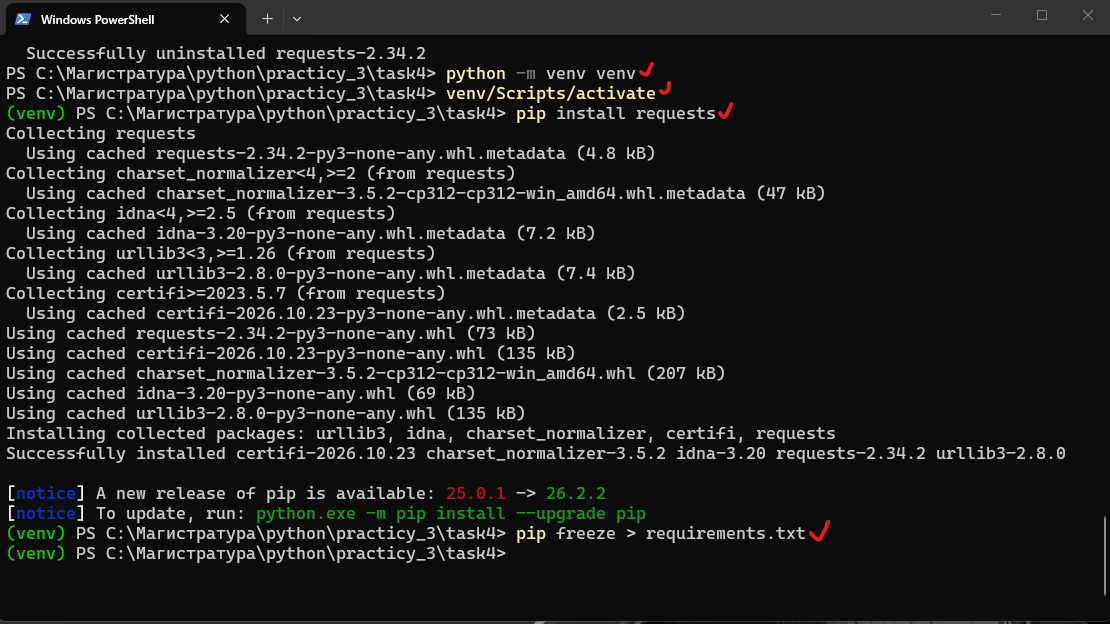

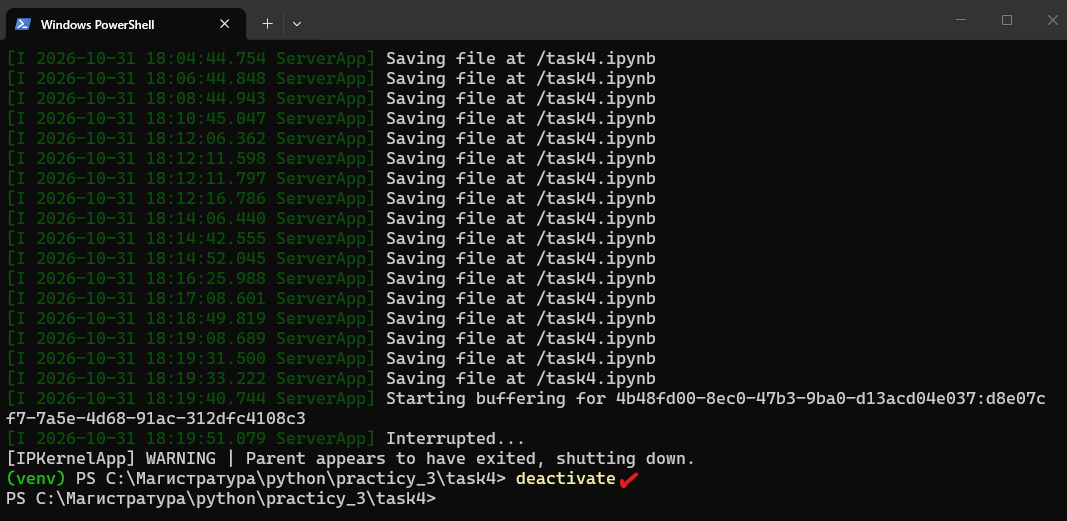